# Entender la ecuación de Bellman en el Q-learning

## ¿Qué es la ecuación de Bellman?

Los valores que busca el Q-learning cumplen una regla sencilla, la **ecuación de Bellman**: tomar la acción $a$ en el estado $s$ vale la recompensa $r$ que aporta, más el valor descontado de la mejor acción desde el estado $s'$ al que lleva:

$$Q(s, a) = r + \gamma \max_{a'} Q(s', a')$$

El agente no conoce estos valores al principio. Así que, después de cada paso, mueve su estimación actual una fracción $\alpha$ del camino hacia el lado derecho de esa ecuación. Esta es la **regla de actualización del Q-learning**:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

Cuando la misma acción puede llevar a estados distintos (en un lago resbaladizo, por ejemplo), la ecuación se cumple en promedio sobre los resultados posibles, y los pequeños pasos de tamaño $\alpha$ son los que los promedian.

La regla de actualización parece compleja, pero vamos a desglosarla en palabras:

**`Valor Q nuevo = Valor Q anterior + Tasa de aprendizaje * (Error de diferencia temporal)`**

Donde:
*   **`Q(s, a)`**: el valor Q actual de estar en el **estado `s`** y tomar la **acción `a`**. Es nuestra estimación anterior.
*   **`α` (alfa)**: la **tasa de aprendizaje** (p. ej., 0,1). Controla cuánto actualizamos nuestro valor Q. Un `α` pequeño significa que aprendemos despacio, y uno grande, que aprendemos rápido.
*   **`r`**: la **recompensa** inmediata que obtenemos después de tomar la acción `a` desde el estado `s`.
*   **`γ` (gamma)**: el **factor de descuento** (p. ej., 0,95). Determina cuánto valoramos las recompensas futuras. Un `γ` cercano a 1 significa que nos importan mucho las recompensas futuras, y uno cercano a 0, que solo nos importa la recompensa inmediata.
*   **`max Q(s', a')`**: el **mejor valor Q posible** que podemos obtener desde nuestro **estado siguiente `s'`**. Es el agente mirando un paso por delante y eligiendo la acción más valiosa desde su nueva posición.
*   **`r + γ * max Q(s', a')`**: este es el **objetivo**: la «estimación nueva y mejor» del valor Q. Es la recompensa inmediata más la estimación descontada de la recompensa futura.
*   **`[...] - Q(s, a)`**: toda esta parte es el **error de diferencia temporal** (*Temporal Difference*, TD). Es la diferencia entre nuestra estimación nueva y la anterior. Representa la «sorpresa», o lo equivocada que estaba nuestra estimación inicial.

## Un ejemplo paso a paso

Simulemos un trocito del mundo `FrozenLake`. Imagina este sencillo entorno de 3 estados:

`Inicio (S0)` <-> `Helado (S1)` <-> `Meta (S2)`

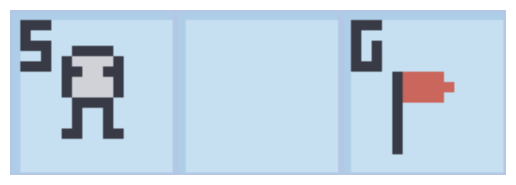

In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt

env = gym.make('FrozenLake-v1', desc=["SFG"], is_slippery=False, render_mode="rgb_array")
env.reset()

def show_env(env):
    '''Render and display the environment in the notebook.'''
    img = env.render()
    plt.imshow(img)
    plt.axis('off')
    plt.show()

show_env(env)

*   **Estados**: S0, S1, S2
*   **Acciones**: 0 (izquierda), 1 (derecha). FrozenLake en sí tiene cuatro acciones (0 izquierda, 1 abajo, 2 derecha, 3 arriba), pero en un lago de una sola fila de alto, abajo y arriba dejan al agente donde está, así que nuestra tabla solo conserva izquierda y derecha.
*   **Recompensas**:
    *   +1 por llegar a la meta (S2)
    *   0 por cualquier otro movimiento.

Fijemos nuestros hiperparámetros:
*   Tasa de aprendizaje (`α`) = 0,1
*   Factor de descuento (`γ`) = 0,9

### Tabla Q inicial

Nuestro agente empieza sin ningún conocimiento. La tabla Q es una matriz `[estados x acciones]` llena de ceros.

$$
\begin{array}{c c}
    & \color{gray} \begin{matrix}
    \text{Izquierda (0)} & \text{Derecha (1)} \end{matrix}
    \\
    \color{gray}
    \begin{matrix} \text{S0} \\ \text{S1} \\ \text{S2} \end{matrix}
    &
    \begin{bmatrix}
        0 & \quad 0 \\
        0 & \quad 0 \\
        0 & \quad 0
    \end{bmatrix}
\end{array}
$$

In [ ]:
import numpy as np

q_table = np.zeros((3, 2)) # 3 estados, 2 acciones

print("Initial Q-Table:")
print(q_table)

Initial Q-Table:
[[0. 0.]
 [0. 0.]
 [0. 0.]]


### El agente se mueve de S0 a S1

1.  **Estado actual (`s`)**: S0
2.  **Acción (`a`)**: 1 (moverse a la derecha)
3.  **Observación**:
    *   Estado nuevo (`s'`) = S1
    *   Recompensa (`r`) = 0

Ahora metamos esto en la ecuación de Bellman para actualizar `Q(S0, Derecha)`.

**Fórmula**: `Q(s, a) = Q(s, a) + α * [r + γ * max Q(s', a') - Q(s, a)]`

**Cálculo**:
*   `Q(S0, Derecha)` = `q_table[0, 1]` = **0**
*   `α` = **0,1**
*   `r` = **0**
*   `γ` = **0,9**
*   `max Q(S1, a')`: el mejor valor Q desde el estado S1. Miramos la fila de S1 en nuestra tabla Q (`q_table[1]`). Los valores son `[0, 0]`. El valor máximo es **0**.

Sustituyamos:
`Nuevo Q(S0, Derecha) = 0 + 0.1 * [0 + 0.9 * 0 - 0]`
`Nuevo Q(S0, Derecha) = 0`

No es muy emocionante. El valor Q no cambió porque no se encontró ninguna recompensa. Esto es habitual al principio del entrenamiento.

### El agente llega a la meta

1.  **Estado actual (`s`)**: S1
2.  **Acción (`a`)**: 1 (moverse a la derecha)
3.  **Observación**:
    *   Estado nuevo (`s'`) = S2 (meta)
    *   Recompensa (`r`) = **+1**

Actualicemos `Q(S1, Derecha)`.

**Cálculo**:
*   `Q(S1, Derecha)` = `q_table[1, 1]` = **0**
*   `α` = **0,1**
*   `r` = **1**
*   `γ` = **0,9**
*   `max Q(S2, a')`: el mejor valor Q desde el estado S2. La fila de S2 en nuestra tabla Q (`q_table[2]`) es `[0, 0]`. El valor máximo es **0**. (S2 es un estado terminal, así que las recompensas futuras desde aquí son 0).

Sustituyamos:
`Nuevo Q(S1, Derecha) = 0 + 0.1 * [1 + 0.9 * 0 - 0]`
`Nuevo Q(S1, Derecha) = 0.1 * [1]`
`Nuevo Q(S1, Derecha) = 0.1`

**¡Esta es nuestra primera actualización!** El agente aprendió que moverse a la derecha desde S1 es ligeramente bueno.

In [ ]:
q_table[1, 1] = 0.1
print("Q-Table after reaching the goal:")
print(q_table)

Q-Table after reaching the goal:
[[0.  0. ]
 [0.  0.1]
 [0.  0. ]]


### Un episodio nuevo: otra vez de S0 a S1

Ahora ocurre la magia. La información de la recompensa empieza a fluir hacia atrás.

1.  **Estado actual (`s`)**: S0
2.  **Acción (`a`)**: 1 (moverse a la derecha)
3.  **Observación**:
    *   Estado nuevo (`s'`) = S1
    *   Recompensa (`r`) = 0

Actualicemos otra vez `Q(S0, Derecha)`.

**Cálculo**:
*   `Q(S0, Derecha)` = `q_table[0, 1]` = **0** (de antes)
*   `α` = **0,1**
*   `r` = **0**
*   `γ` = **0,9**
*   `max Q(S1, a')`: **¡esta es la diferencia clave!** Miramos la fila de S1 en nuestra tabla Q actualizada (`q_table[1]`). Los valores son `[0, 0.1]`. El valor máximo es ahora **0,1**.

Sustituyamos:
`Nuevo Q(S0, Derecha) = 0 + 0.1 * [0 + 0.9 * 0.1 - 0]`
`Nuevo Q(S0, Derecha) = 0.1 * [0.09]`
`Nuevo Q(S0, Derecha) = 0.009`

¡El valor de estar en `S0` y moverse a la derecha ha aumentado! El agente está aprendiendo que esta acción lleva a un estado (S1) que tiene un valor futuro conocido y positivo. La recompensa de llegar a la meta se propaga poco a poco hacia atrás, a los estados que llevan a ella.

In [ ]:
q_table[0, 1] = 0.009
print("Q-Table after the new episode's first move:")
print(q_table)

Q-Table after the new episode's first move:
[[0.    0.009]
 [0.    0.1  ]
 [0.    0.   ]]


## Cómo se ve en código

El bucle de entrenamiento del [notebook 3](frozen_lake.ipynb) repite esta actualización miles de veces, hasta que la recompensa ha fluido hacia atrás desde la meta hasta todos los estados que llevan a ella. Esta es su línea de actualización, asociada a nuestro último cálculo: cada variable es un término de la ecuación.

In [ ]:
# Del bucle de entrenamiento:
# Qtable[state][action] = Qtable[state][action] + learning_rate * (
#     reward + gamma * np.max(Qtable[new_state]) - Qtable[state][action]
# )

# Asociémoslo a nuestro último cálculo:
s = 0
a = 1
s_prime = 1
r = 0

learning_rate = 0.1
gamma = 0.9

# q_table antes de la actualización
q_table_before = np.array([[0., 0.], [0., 0.1], [0., 0.]])

# La actualización de Bellman en código
old_q_value = q_table_before[s, a]                 # Q(s, a)
max_future_q = np.max(q_table_before[s_prime])   # max Q(s', a')
td_error = r + gamma * max_future_q - old_q_value

new_q_value = old_q_value + learning_rate * td_error

print(f"Old Q-value: {old_q_value}")
print(f"Max future Q-value from S{s_prime}: {max_future_q}")
print(f"TD Error: {td_error:.3f}")
print(f"New Q-value for Q(S{s}, Right): {new_q_value:.3f}")

Old Q-value: 0.0
Max future Q-value from S1: 0.1
TD Error: 0.090
New Q-value for Q(S0, Right): 0.009
